# Universidad del Valle de Guatemala
## CC3084 - Data Science
### Laboratorio 1 — Series de Tiempo

#### Cristian Tunchez - 231359  
#### Nadissa Vela - 23764

## Categoría 3.b.ii — Regiones geográficas (top 3 por total acumulado)

**Ejercicio 4**, aplicado a las tres series mensuales de la categoría
**Región dos**: **América del Centro**, **América del Norte** y **Europa**
(seleccionadas y exportadas en `02_preparacion_series.ipynb` por ser las tres
regiones con mayor número acumulado de visitantes 2009–jun 2026).

El pipeline (descripción, descomposición, ADF, ACF/PACF, selección de ARIMA,
benchmarks Holt-Winters/suavizamiento exponencial/seasonal naive/Prophet,
pronóstico y comparación de métricas) es idéntico al usado para la serie
Total en `03_serie_total.ipynb`; para no repetir ~250 líneas de código tres
veces, toda la lógica común vive en `src/ts_utils.py`
(`analizar_serie_completa`) y aquí solo se invoca una vez por serie.

## Configuración del entorno

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import ts_utils as tsu

pd.set_option("display.max_columns", 40)
panel = pd.read_csv("../data/processed/series_mensuales.csv", parse_dates=["fecha"])

def cargar(nombre_serie):
    sub = panel[panel["serie"] == nombre_serie].sort_values("fecha")
    s = sub.set_index("fecha")["viajeros"].asfreq("MS")
    train = s[sub.set_index("fecha")["conjunto"] == "train"]
    test = s[sub.set_index("fecha")["conjunto"] == "test"]
    return train, test

SERIES_REGION = {
    "América del Centro": "region_america_central",
    "América del Norte":  "region_america_norte",
    "Europa":             "region_europa",
}
print("Series de la categoría Regiones geográficas:", list(SERIES_REGION.keys()))


Series de la categoría Regiones geográficas: ['América del Centro', 'América del Norte', 'Europa']


## 1. América del Centro

SERIE: América del Centro
Serie: América del Centro
  Inicio:        2009-01
  Fin:           2026-06
  Frecuencia:    MS
  Observaciones: 210
  Faltantes:     0


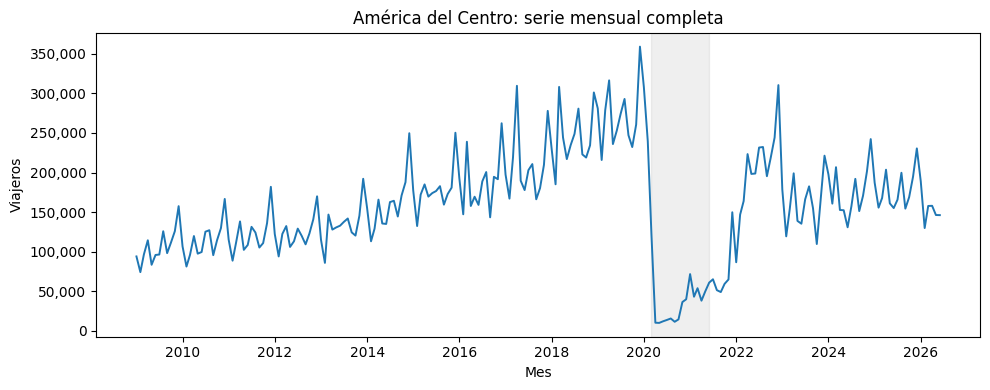

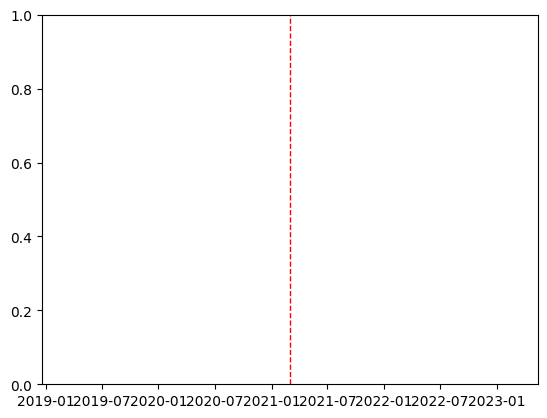

Correlación nivel medio anual vs. desviación estándar anual (sin 2020-2021): 0.85
-> Se usa descomposición multiplicative (la amplitud estacional crece con el nivel).


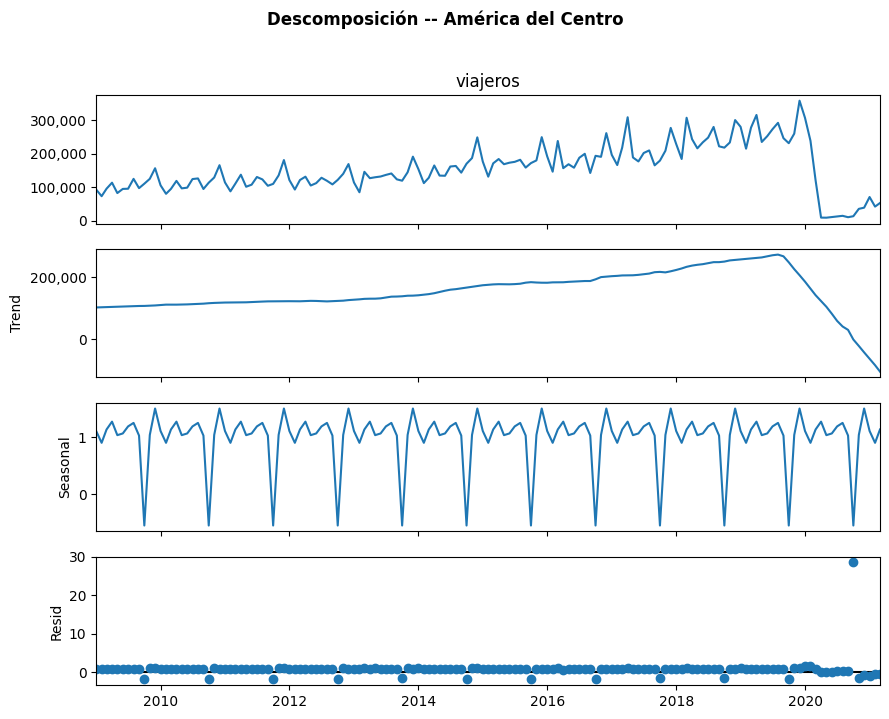

Transformación aplicada: logaritmo (np.log).

ADF sobre la serie (transformada) en nivel:
ADF (América del Centro): estadístico=-2.2164  p-valor=0.2003  lags usados=12  n obs=134
  Valores críticos: {'1%': np.float64(-3.48), '5%': np.float64(-2.883), '10%': np.float64(-2.578)}
  Conclusión (alpha=0.05): la serie es NO estacionaria en media.

Búsqueda de 'd' (diferenciación regular):
  d=0: ADF p-valor=0.2003
  d=1: ADF p-valor=0.0358
  -> Diferenciaciones necesarias: d=1


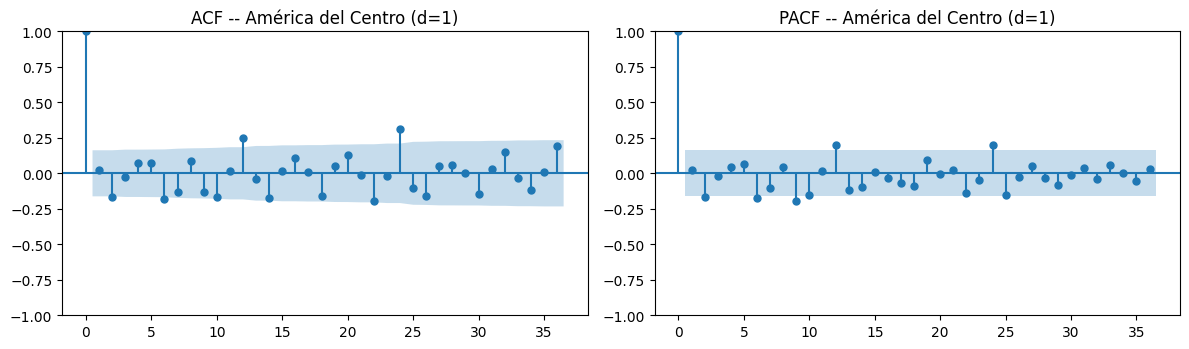


ADF tras diferenciación regular + estacional (D=1):
ADF (América del Centro, d+D=1(12)): estadístico=-6.2738  p-valor=0.0000  lags usados=11  n obs=122
  Valores críticos: {'1%': np.float64(-3.485), '5%': np.float64(-2.886), '10%': np.float64(-2.58)}
  Conclusión (alpha=0.05): la serie es ESTACIONARIA en media.

Elección manual (ACF/PACF): order=(1, 1, 1)  seasonal_order=(1, 1, 1, 12)
auto_arima:                 order=(1, 0, 1)  seasonal_order=(1, 0, 2, 12)


,modelo,order,seasonal_order,AIC,BIC,media_residuo,std_residuo
0,"(1, 1, 0)x(1, 1, 0, 12)","(1, 1, 0)","(1, 1, 0, 12)",50.366752,59.060271,0.030128,1.108199
1,"(1, 0, 1)x(1, 0, 2, 12)","(1, 0, 1)","(1, 0, 2, 12)",53.663226,74.596254,-0.000181,0.271829
2,"(1, 1, 1)x(1, 1, 1, 12)","(1, 1, 1)","(1, 1, 1, 12)",53.852481,68.341680,0.029691,1.108017
3,"(0, 1, 1)x(0, 1, 1, 12)","(0, 1, 1)","(0, 1, 1, 12)",55.511022,64.204542,0.029864,1.109710


Mejor ARIMA por AIC: (1, 1, 0)x(1, 1, 0, 12)


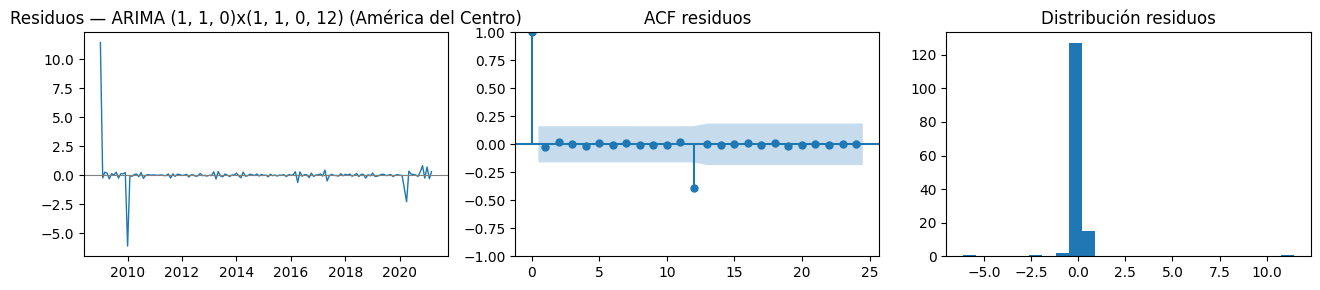

Ljung-Box (ARIMA (1, 1, 0)x(1, 1, 0, 12) (América del Centro)):


,lb_stat,lb_pvalue
12,25.544641,0.012443
24,25.639375,0.371713


Importing plotly failed. Interactive plots will not work.


  -> Aún queda autocorrelación en los residuos (p-valor < 0.05 en algún lag).


16:23:16 - cmdstanpy - INFO - Chain [1] start processing
16:23:16 - cmdstanpy - INFO - Chain [1] done processing


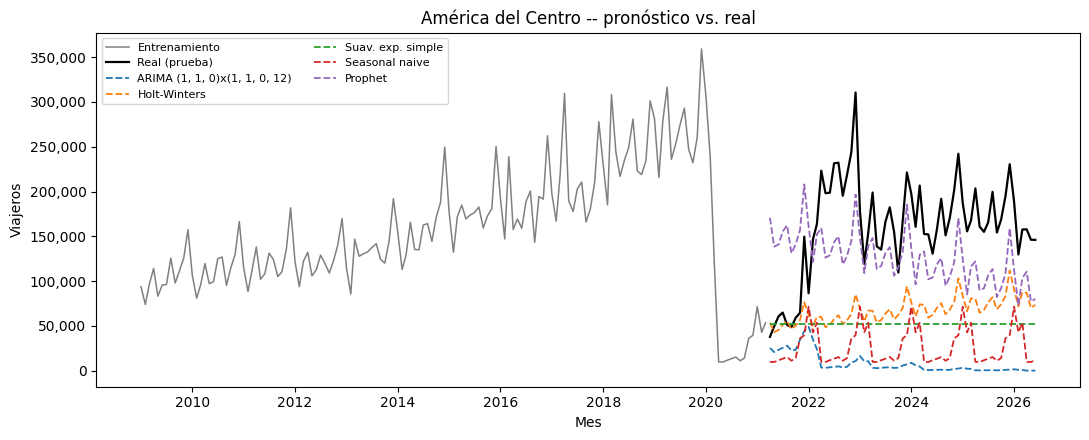

,modelo,MAE,RMSE,AIC,BIC
0,Prophet,"62,485","67,838",nan,nan
1,Holt-Winters,"94,089","105,019","3,027.1","3,074.9"
2,Suav. exp. simple,"109,867","121,961","3,114.9","3,120.8"
3,Seasonal naive,"134,400","144,899",nan,nan
4,"ARIMA (1, 1, 0)x(1, 1, 0, 12)","152,658","164,461",50.4,59.1


Mejor modelo para América del Centro: Prophet  (MAE=62,485, RMSE=67,838)


In [2]:
train_ac, test_ac = cargar("region_america_central")
resultado_ac = tsu.analizar_serie_completa("América del Centro", train_ac, test_ac, periodo=12)


## 2. América del Norte

SERIE: América del Norte
Serie: América del Norte
  Inicio:        2009-01
  Fin:           2026-06
  Frecuencia:    MS
  Observaciones: 210
  Faltantes:     0


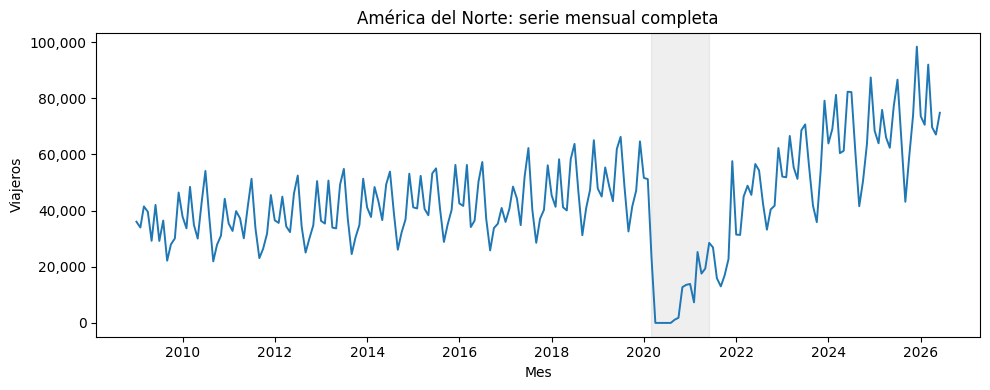

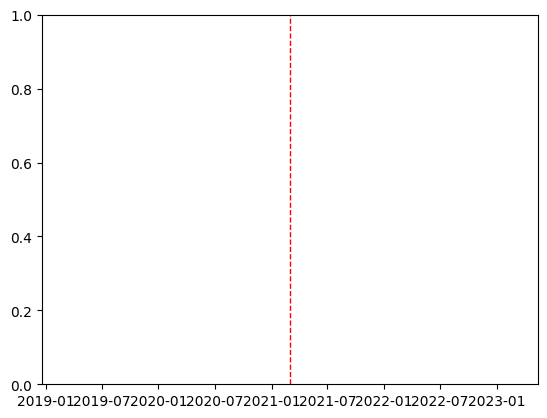

Correlación nivel medio anual vs. desviación estándar anual (sin 2020-2021): 0.79
  Nota: la serie tiene meses en 0 (cierre total de fronteras en pandemia) -> la descomposición multiplicativa y el logaritmo no están definidos ahí; se usa aditiva.
-> Se usa descomposición additive (la amplitud estacional es aprox. constante o hay ceros en la serie).


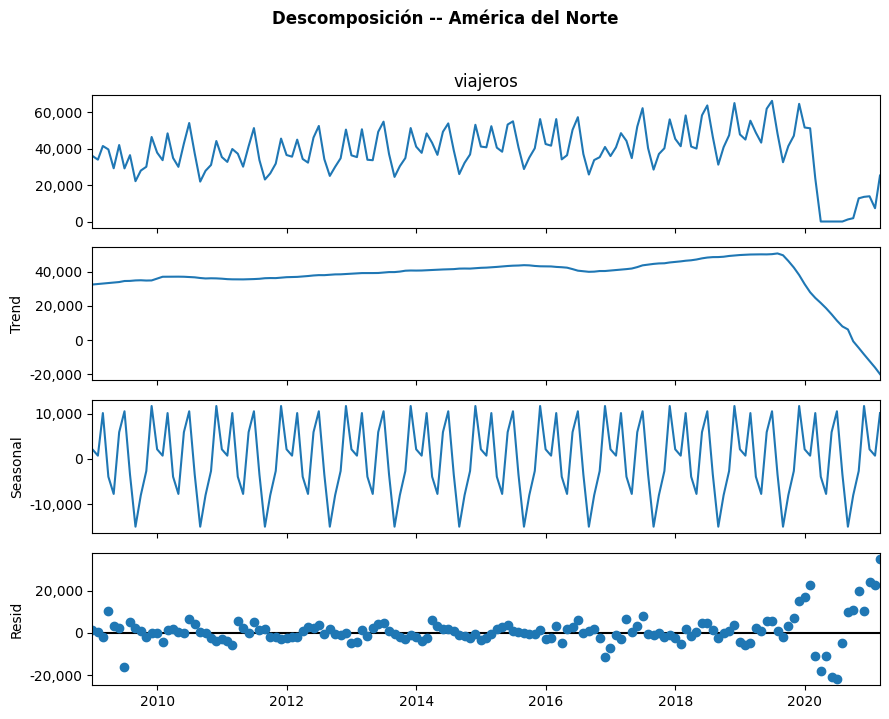

Transformación aplicada: ninguna.

ADF sobre la serie (transformada) en nivel:
ADF (América del Norte): estadístico=-3.4199  p-valor=0.0103  lags usados=13  n obs=133
  Valores críticos: {'1%': np.float64(-3.481), '5%': np.float64(-2.884), '10%': np.float64(-2.578)}
  Conclusión (alpha=0.05): la serie es ESTACIONARIA en media.

Búsqueda de 'd' (diferenciación regular):
  d=0: ADF p-valor=0.0103
  -> Diferenciaciones necesarias: d=0


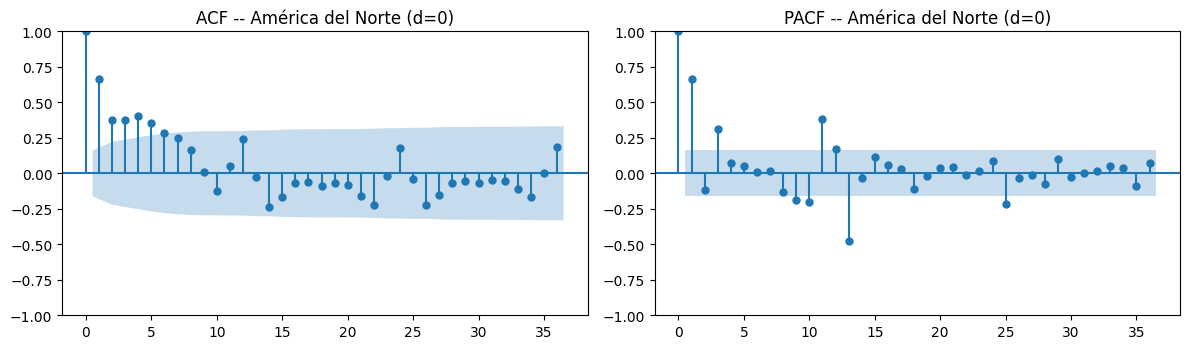


ADF tras diferenciación regular + estacional (D=1):
ADF (América del Norte, d+D=1(12)): estadístico=-2.6007  p-valor=0.0928  lags usados=12  n obs=122
  Valores críticos: {'1%': np.float64(-3.485), '5%': np.float64(-2.886), '10%': np.float64(-2.58)}
  Conclusión (alpha=0.05): la serie es NO estacionaria en media.

Elección manual (ACF/PACF): order=(1, 0, 1)  seasonal_order=(1, 1, 1, 12)
auto_arima:                 order=(3, 0, 2)  seasonal_order=(2, 0, 0, 12)


,modelo,order,seasonal_order,AIC,BIC,media_residuo,std_residuo
0,"(1, 0, 1)x(1, 1, 1, 12)","(1, 0, 1)","(1, 1, 1, 12)",2796.845107,2811.371480,880.034321,8452.513563
1,"(1, 0, 0)x(1, 1, 0, 12)","(1, 0, 0)","(1, 1, 0, 12)",2805.202835,2813.918659,567.053826,8874.595117
2,"(0, 0, 1)x(0, 1, 1, 12)","(0, 0, 1)","(0, 1, 1, 12)",2899.074076,2907.789900,2171.097177,12171.222569
3,"(3, 0, 2)x(2, 0, 0, 12)","(3, 0, 2)","(2, 0, 0, 12)",3068.166804,3095.080697,-309.034636,7001.058567


Mejor ARIMA por AIC: (1, 0, 1)x(1, 1, 1, 12)


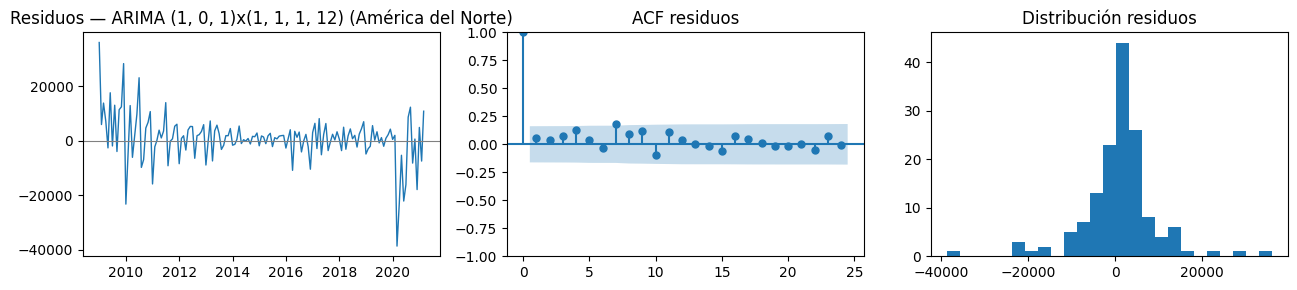

Ljung-Box (ARIMA (1, 0, 1)x(1, 1, 1, 12) (América del Norte)):


,lb_stat,lb_pvalue
12,17.040260,0.148089
24,20.520617,0.666818


16:23:29 - cmdstanpy - INFO - Chain [1] start processing
16:23:29 - cmdstanpy - INFO - Chain [1] done processing


  -> Residuos compatibles con ruido blanco (no autocorrelación).


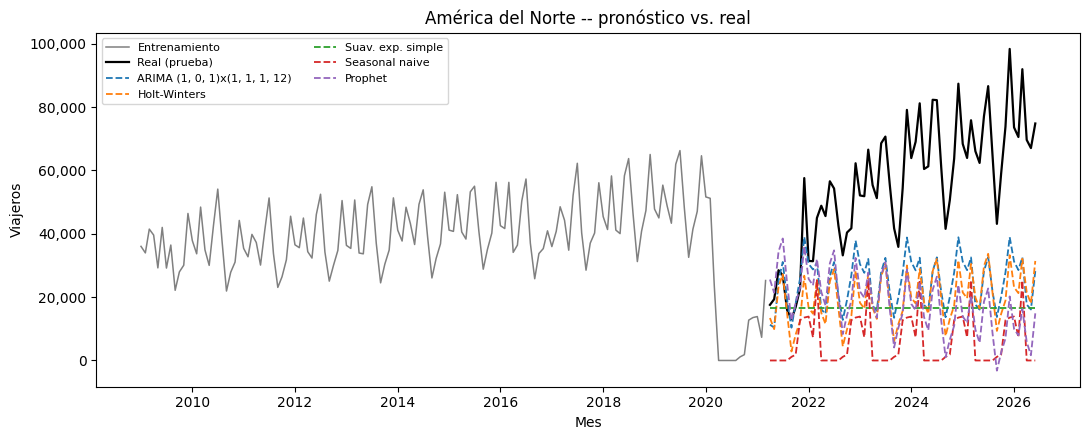

,modelo,MAE,RMSE,AIC,BIC
0,"ARIMA (1, 0, 1)x(1, 1, 1, 12)","31,546","35,422","2,796.8","2,811.4"
1,Holt-Winters,"36,224","39,269","2,576.7","2,624.5"
2,Suav. exp. simple,"39,603","44,300","2,735.1","2,741.1"
3,Prophet,"39,278","44,358",nan,nan
4,Seasonal naive,"49,974","53,533",nan,nan


Mejor modelo para América del Norte: ARIMA (1, 0, 1)x(1, 1, 1, 12)  (MAE=31,546, RMSE=35,422)


In [3]:
train_an, test_an = cargar("region_america_norte")
resultado_an = tsu.analizar_serie_completa("América del Norte", train_an, test_an, periodo=12)


## 3. Europa

SERIE: Europa
Serie: Europa
  Inicio:        2009-01
  Fin:           2026-06
  Frecuencia:    MS
  Observaciones: 210
  Faltantes:     0


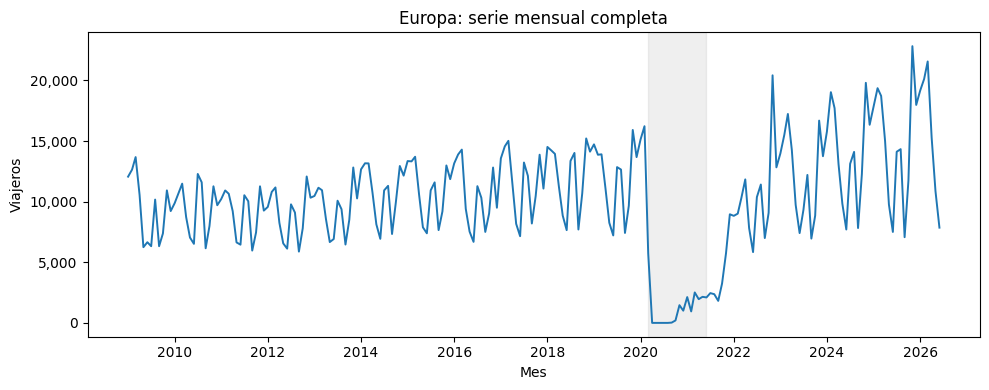

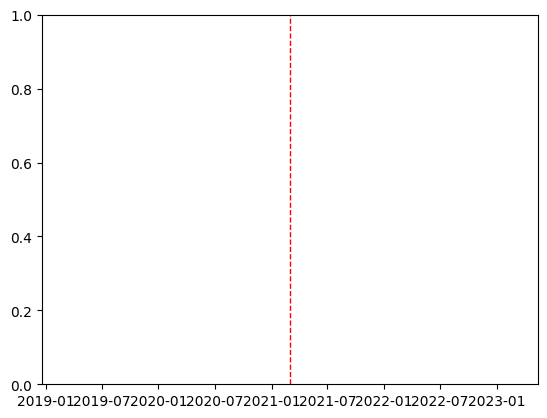

Correlación nivel medio anual vs. desviación estándar anual (sin 2020-2021): 0.76
  Nota: la serie tiene meses en 0 (cierre total de fronteras en pandemia) -> la descomposición multiplicativa y el logaritmo no están definidos ahí; se usa aditiva.
-> Se usa descomposición additive (la amplitud estacional es aprox. constante o hay ceros en la serie).


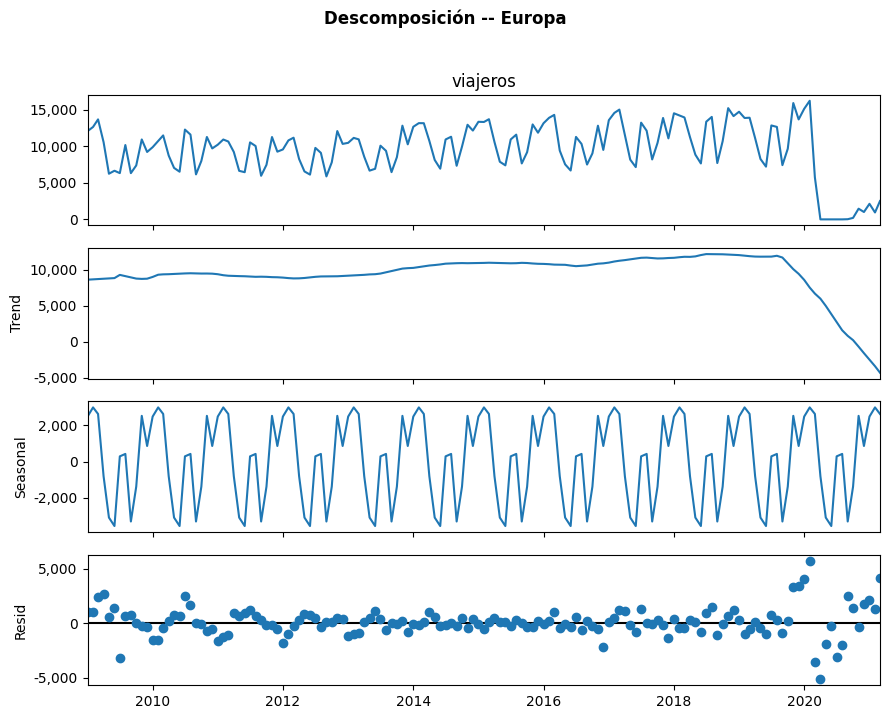

Transformación aplicada: ninguna.

ADF sobre la serie (transformada) en nivel:
ADF (Europa): estadístico=-2.4738  p-valor=0.1220  lags usados=14  n obs=132
  Valores críticos: {'1%': np.float64(-3.481), '5%': np.float64(-2.884), '10%': np.float64(-2.579)}
  Conclusión (alpha=0.05): la serie es NO estacionaria en media.

Búsqueda de 'd' (diferenciación regular):
  d=0: ADF p-valor=0.1220
  d=1: ADF p-valor=0.4853
  d=2: ADF p-valor=0.0000
  -> Diferenciaciones necesarias: d=2


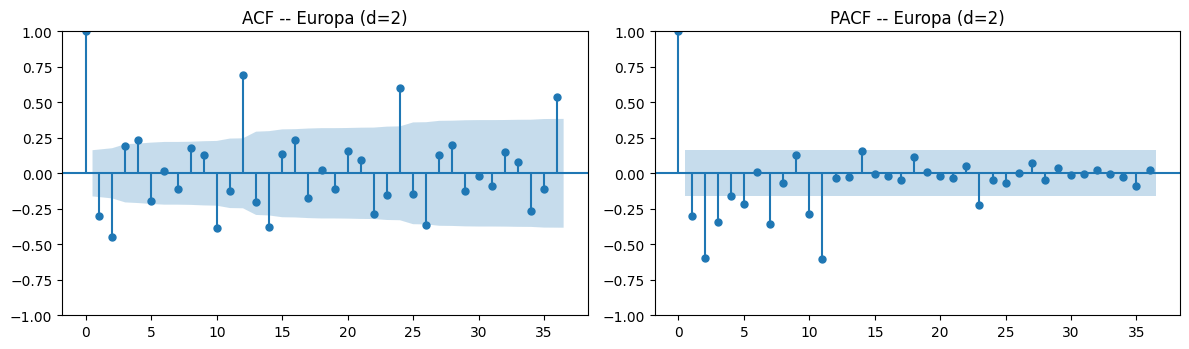


ADF tras diferenciación regular + estacional (D=1):
ADF (Europa, d+D=1(12)): estadístico=-4.1707  p-valor=0.0007  lags usados=12  n obs=120
  Valores críticos: {'1%': np.float64(-3.486), '5%': np.float64(-2.886), '10%': np.float64(-2.58)}
  Conclusión (alpha=0.05): la serie es ESTACIONARIA en media.

Elección manual (ACF/PACF): order=(1, 2, 1)  seasonal_order=(1, 1, 1, 12)
auto_arima:                 order=(1, 0, 0)  seasonal_order=(0, 0, 2, 12)


,modelo,order,seasonal_order,AIC,BIC,media_residuo,std_residuo
0,"(0, 2, 1)x(0, 1, 1, 12)","(0, 2, 1)","(0, 1, 1, 12)",2367.300200,2375.971248,98.327455,2273.480284
1,"(1, 2, 1)x(1, 1, 1, 12)","(1, 2, 1)","(1, 1, 1, 12)",2370.262025,2384.713771,102.062681,2273.662276
2,"(1, 2, 0)x(1, 1, 0, 12)","(1, 2, 0)","(1, 1, 0, 12)",2463.110030,2471.781078,56.248687,2906.606622
3,"(1, 0, 0)x(0, 0, 2, 12)","(1, 0, 0)","(0, 0, 2, 12)",2656.909109,2671.861272,-106.636437,1970.118229


Mejor ARIMA por AIC: (0, 2, 1)x(0, 1, 1, 12)


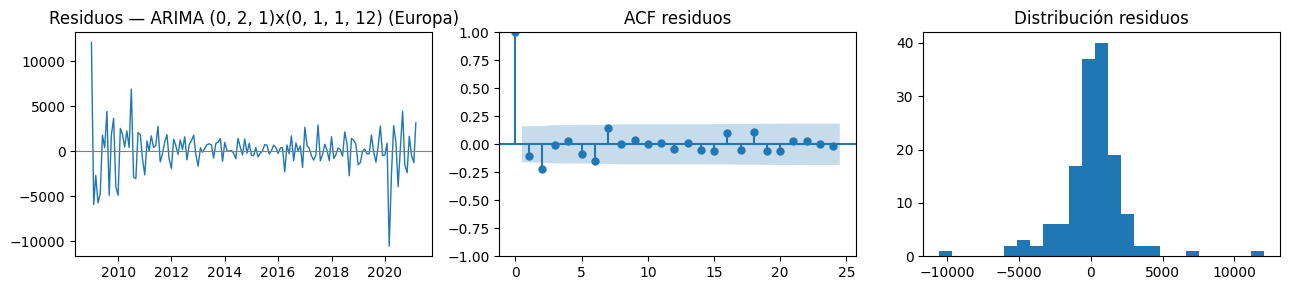

Ljung-Box (ARIMA (0, 2, 1)x(0, 1, 1, 12) (Europa)):


,lb_stat,lb_pvalue
12,17.558650,0.129763
24,24.559309,0.430015


16:23:36 - cmdstanpy - INFO - Chain [1] start processing
16:23:36 - cmdstanpy - INFO - Chain [1] done processing


  -> Residuos compatibles con ruido blanco (no autocorrelación).


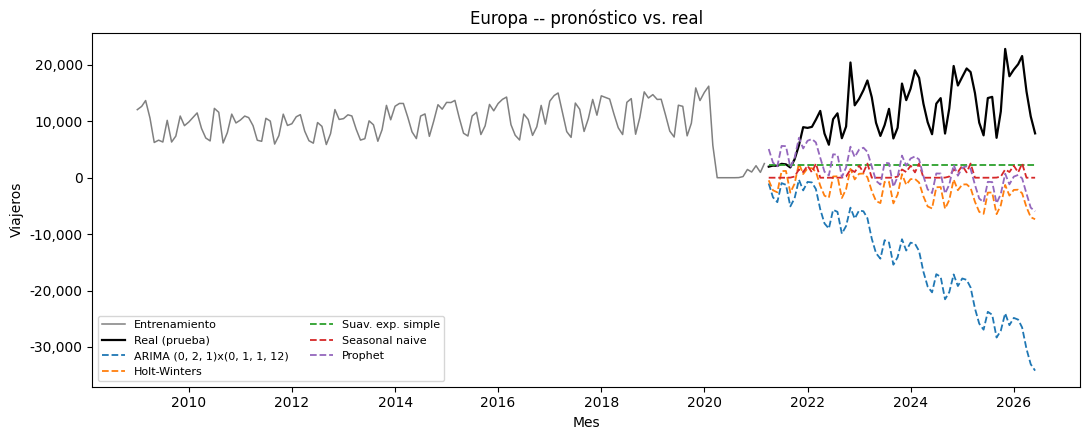

,modelo,MAE,RMSE,AIC,BIC
0,Suav. exp. simple,"9,571","10,978","2,329.7","2,335.6"
1,Prophet,"10,727","12,126",nan,nan
2,Seasonal naive,"11,075","12,135",nan,nan
3,Holt-Winters,"13,784","14,875","2,175.4","2,223.3"
4,"ARIMA (0, 2, 1)x(0, 1, 1, 12)","25,848","28,686","2,367.3","2,376.0"


Mejor modelo para Europa: Suav. exp. simple  (MAE=9,571, RMSE=10,978)


In [4]:
train_eu, test_eu = cargar("region_europa")
resultado_eu = tsu.analizar_serie_completa("Europa", train_eu, test_eu, periodo=12)


## 4. Resumen comparativo de la categoría (insumo para el ejercicio 5)

In [5]:
resumen = pd.DataFrame([
    {"región": r["nombre"], "d": r["d"], "D": r["D"], "descomposición": r["modelo_decomp"],
     "mejor_modelo": r["mejor_modelo"], "MAE": r["mejor_mae"], "RMSE": r["mejor_rmse"],
     "corr_nivel_std": r["corr_nivel_std"]}
    for r in [resultado_ac, resultado_an, resultado_eu]
])
display(resumen.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "corr_nivel_std": "{:.2f}"}))

resumen.to_csv("../data/processed/resumen_regiones.csv", index=False)
print("Guardado: data/processed/resumen_regiones.csv (insumo para 06_analisis_comparativo.ipynb)")


,región,d,D,descomposición,mejor_modelo,MAE,RMSE,corr_nivel_std
0,América del Centro,1,1,multiplicative,Prophet,"62,485","67,838",0.85
1,América del Norte,0,1,additive,"ARIMA (1, 0, 1)x(1, 1, 1, 12)","31,546","35,422",0.79
2,Europa,2,1,additive,Suav. exp. simple,"9,571","10,978",0.76


Guardado: data/processed/resumen_regiones.csv (insumo para 06_analisis_comparativo.ipynb)


## 5. Conclusiones de la categoría

- Las tres regiones comparten la forma general de la serie Total (tendencia
  2009-2019, colapso pandémico, recuperación), porque son subconjuntos
  aditivos del mismo fenómeno migratorio, pero **difieren en escala,
  estacionalidad y velocidad de recuperación** — la tabla de la sección 4
  resume, para esta ejecución concreta, qué orden de diferenciación (`d`,`D`)
  necesitó cada una y qué modelo ganó.
- Estas diferencias (mayor/menor estacionalidad, tendencia, volatilidad,
  afectación por la pandemia) se retoman de forma explícitamente comparativa
  en `06_analisis_comparativo.ipynb` (ejercicio 5), usando tanto esta tabla
  como los gráficos y descomposiciones producidos en las secciones 1-3.
